# Submission 03 



In this submission, I focused more on improving the data because parameter tuning in Submission 2 gave only a small improvement.

I cleaned inconsistent diagnosis codes and lab values, and created more detailed features from the existing data. For example, instead of just counting how many diagnoses a patient had, I used pd.crosstab() to create separate columns for diagnosis codes, such as dx_E11 for diabetes. I also used one-hot encoding for categorical features and calculated the minimum, maximum, and average values of lab tests.

These changes increased the features from 34 to 346, giving the model more information about each patient. I then compared different scaling methods and Logistic Regression settings. The best ROC-AUC improved from 0.7380 to 0.7476.

## Import Libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
SEED = 42

## Load Dataset

In [2]:
paths = ['/kaggle/input/competitions/machine-learning-fall-26-challenge-1-iba-karachi/',
         '/kaggle/input/machine-learning-fall-26-challenge-1-iba-karachi/',
         './']
D = next(p for p in paths if os.path.exists(p + 'train.csv'))

train = pd.read_csv(D + 'train.csv')
test = pd.read_csv(D + 'test.csv')
encounters = pd.read_csv(D + 'index_encounters.csv')
patients = pd.read_csv(D + 'patients.csv')
hospitals = pd.read_csv(D + 'hospitals.csv')
diagnoses = pd.read_csv(D + 'diagnoses.csv')
icd_lookup = pd.read_csv(D + 'icd10_lookup.csv')
procedures = pd.read_csv(D + 'procedures.csv')
labs = pd.read_csv(D + 'lab_results.csv')
vitals = pd.read_csv(D + 'vitals.csv')
meds = pd.read_csv(D + 'medications.csv')
transfers = pd.read_csv(D + 'unit_transfers.csv')
prior = pd.read_csv(D + 'prior_utilization.csv')
planning = pd.read_csv(D + 'discharge_planning.csv')

## Data Cleaning Carried Over from Submission 01

In [3]:
patients['insurance_type'] = patients.insurance_type.str.upper()
patients['race_ethnicity'] = patients.race_ethnicity.replace({'?': 'Unknown'})
patients.loc[patients.birth_year <= 1900, 'birth_year'] = np.nan

encounters['admit_dt'] = pd.to_datetime(encounters.admit_dt)
encounters['discharge_dt'] = pd.to_datetime(encounters.discharge_dt)

planning['home_health_referral'] = (planning.home_health_referral == 'Y').astype(int)
planning['education_done'] = planning.education_done.map({'Yes': 1, 'No': 0})

## Cleaning Diagnosis Codes

In [4]:
print('Lookup match before cleaning:', diagnoses.icd10_code.isin(icd_lookup.icd10_code).mean().round(3))

def clean_icd(code):
    code = str(code).strip().upper().replace('.', '')
    return code[:3] + '.' + code[3:] if len(code) > 3 else code

diagnoses['icd10_code'] = diagnoses.icd10_code.map(clean_icd)
diagnoses = diagnoses.merge(icd_lookup[['icd10_code', 'chapter', 'chronic_flag']], on='icd10_code', how='left')
print('Lookup match after cleaning: ', diagnoses.chapter.notna().mean().round(3))

Lookup match before cleaning: 0.725
Lookup match after cleaning:  1.0


## Cleaning Lab Units

In [5]:
labs.groupby(['lab_name', 'unit'], dropna=False).value.median().unstack().round(2)

unit,%,10^3/uL,g/L,g/dL,mg/dL,mmol/L,ng/mL,pg/mL,ratio,umol/L,NaN
lab_name,,,,,,,,,,,
Albumin,NaN,NaN,35.0,3.5,NaN,NaN,NaN,NaN,NaN,NaN,3.90
Bnp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,687.0,NaN,NaN,648.00
Bun,NaN,NaN,NaN,NaN,21.00,NaN,NaN,NaN,NaN,NaN,21.00
Creatinine,NaN,NaN,NaN,NaN,1.18,NaN,NaN,NaN,NaN,105.0,1.36
Glucose,NaN,NaN,NaN,NaN,137.00,7.6,NaN,NaN,NaN,NaN,129.00
Hba1C,7.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.50
Hemoglobin,NaN,NaN,121.0,12.1,NaN,NaN,NaN,NaN,NaN,NaN,13.30
Inr,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.15,NaN,1.15
Lactate,NaN,NaN,NaN,NaN,NaN,2.4,NaN,NaN,NaN,NaN,2.30


In [6]:
to_standard = {('Albumin', 'g/L'): 0.1, ('Hemoglobin', 'g/L'): 0.1,
               ('Creatinine', 'umol/L'): 1 / 88.4, ('Glucose', 'mmol/L'): 18.0}
labs['value_std'] = labs.value * [to_standard.get(k, 1.0) for k in zip(labs.lab_name, labs.unit)]

no_unit = labs.unit.isna()
labs.loc[no_unit & labs.lab_name.isin(['Albumin']) & (labs.value > 10), 'value_std'] *= 0.1
labs.loc[no_unit & labs.lab_name.isin(['Hemoglobin']) & (labs.value > 30), 'value_std'] *= 0.1
labs.loc[no_unit & labs.lab_name.isin(['Creatinine']) & (labs.value > 25), 'value_std'] /= 88.4
labs.loc[no_unit & labs.lab_name.isin(['Glucose']) & (labs.value < 35), 'value_std'] *= 18.0

limits = {'Sodium': (110, 180), 'Potassium': (1.5, 9), 'Glucose': (20, 1200), 'Creatinine': (0.1, 25),
          'Bun': (1, 250), 'Hemoglobin': (2, 25), 'Wbc': (0.1, 150), 'Albumin': (0.5, 7),
          'Lactate': (0.1, 30), 'Troponin_I': (0, 100), 'Bnp': (0, 50000), 'Hba1C': (3, 20), 'Inr': (0.5, 15)}
for name, (low, high) in limits.items():
    rows = labs.lab_name == name
    for _ in range(2):
        labs.loc[rows & (labs.value_std > high), 'value_std'] /= 10
    labs.loc[rows & ~labs.value_std.between(low, high), 'value_std'] = np.nan

labs.groupby('lab_name').value_std.median().round(2)

lab_name
Albumin         3.50
Bnp           686.00
Bun            21.00
Creatinine      1.18
Glucose       137.00
Hba1C           7.40
Hemoglobin     12.10
Inr             1.15
Lactate         2.40
Potassium       4.20
Sodium        138.00
Troponin_I      0.03
Wbc             9.60
Name: value_std, dtype: float64

## Cleaning Vital Signs

In [7]:
vitals['charttime'] = pd.to_datetime(vitals.charttime, format='%m/%d/%Y %H:%M')
fahrenheit = (vitals.vital_type == 'TEMP') & (vitals.value > 45)
vitals.loc[fahrenheit, 'value'] = (vitals.loc[fahrenheit, 'value'] - 32) * 5 / 9
vitals.loc[(vitals.vital_type == 'SPO2') & (vitals.value < 50), 'value'] = np.nan
vitals.loc[(vitals.vital_type == 'HR') & (vitals.value > 220), 'value'] = np.nan

print('Temperatures converted from Fahrenheit:', fahrenheit.sum())
vitals.groupby('vital_type').value.describe().round(1)

Temperatures converted from Fahrenheit: 66538


,count,mean,std,min,25%,50%,75%,max
vital_type,,,,,,,,
DBP,377723.0,79.2,11.8,28.0,71.0,79.0,87.0,130.0
HR,377418.0,80.1,12.9,29.0,71.0,80.0,89.0,147.0
RR,377833.0,18.0,2.8,7.0,16.0,18.0,20.0,32.0
SBP,377926.0,128.8,16.7,57.0,118.0,129.0,140.0,210.0
SPO2,378001.0,95.8,2.1,86.0,94.0,96.0,97.0,100.0
TEMP,378097.0,36.9,0.4,35.2,36.7,36.9,37.1,38.5


## Base Features from Submission 01

In [8]:
df = (encounters
      .merge(patients, on='patient_id', how='left')
      .merge(hospitals, on='hospital_id', how='left')
      .merge(planning, on='encounter_id', how='left'))

df['age'] = df.admit_dt.dt.year - df.birth_year
df['los_days'] = (df.discharge_dt - df.admit_dt).dt.total_seconds() / 86400

counts = {
    'n_diagnoses': diagnoses.groupby('encounter_id').size(),
    'n_procedures': procedures.groupby('encounter_id').size(),
    'n_labs': labs.groupby('encounter_id').size(),
    'n_labs_abnormal': labs[labs.abnormal_flag.isin(['H', 'L'])].groupby('encounter_id').size(),
    'n_vitals': vitals.groupby('encounter_id').size(),
    'n_medications': meds.groupby('encounter_id').size(),
    'n_meds_at_discharge': meds[meds.continued_at_discharge == 1].groupby('encounter_id').size(),
    'n_unit_transfers': transfers.groupby('encounter_id').size(),
    'n_icu_stays': transfers[transfers.unit == 'ICU'].groupby('encounter_id').size(),
}
for name, s in counts.items():
    df[name] = df.encounter_id.map(s).fillna(0)

prior_counts = pd.crosstab(prior.patient_id, prior.visit_type).add_prefix('prior_')
df = df.merge(prior_counts, left_on='patient_id', right_index=True, how='left')
df[prior_counts.columns] = df[prior_counts.columns].fillna(0)

base_num = ['age', 'los_days', 'deprivation_index', 'bed_size', 'teaching_flag',
            'n_diagnoses', 'n_procedures', 'n_labs', 'n_labs_abnormal', 'n_vitals',
            'n_medications', 'n_meds_at_discharge', 'n_unit_transfers', 'n_icu_stays',
            'prior_ED', 'prior_IP', 'prior_OP',
            'followup_scheduled_days', 'home_health_referral', 'med_reconciliation_done', 'education_done']
base_cat = ['hospital_id', 'admission_type', 'admission_source', 'service_line', 'discharge_disposition',
            'attending_specialty', 'sex', 'race_ethnicity', 'language', 'marital_status',
            'insurance_type', 'urban_rural', 'ownership']

## Stay Timing Features

In [9]:
stay = pd.DataFrame(index=df.encounter_id)
stay['admit_weekend'] = (df.admit_dt.dt.dayofweek >= 5).astype(int).values
stay['discharge_weekend'] = (df.discharge_dt.dt.dayofweek >= 5).astype(int).values
stay['discharge_hour'] = df.discharge_dt.dt.hour.values
stay['admit_weight_kg'] = df.admit_weight_kg.values
stay['followup_within_7d'] = (df.followup_scheduled_days <= 7).astype(int).values

## Diagnosis Features

In [10]:
dx = pd.DataFrame({
    'n_dx_chronic': diagnoses.groupby('encounter_id').chronic_flag.sum(),
    'n_dx_unique': diagnoses.groupby('encounter_id').icd10_code.nunique(),
    'n_dx_chapters': diagnoses.groupby('encounter_id').chapter.nunique(),
    'n_dx_hospital_acquired': diagnoses[diagnoses.present_on_admission == 'N'].groupby('encounter_id').size(),
})
dx_chapter = pd.crosstab(diagnoses.encounter_id, diagnoses.chapter).add_prefix('chapter_')
dx_code = pd.crosstab(diagnoses.encounter_id, diagnoses.icd10_code).clip(upper=1).add_prefix('dx_')

primary = diagnoses[diagnoses.is_primary == 1].drop_duplicates('encounter_id').set_index('encounter_id')
df['primary_dx'] = df.encounter_id.map(primary.icd10_code)
df['primary_chapter'] = df.encounter_id.map(primary.chapter)
dx['primary_chronic'] = primary.chronic_flag

dx = dx.join(dx_chapter).join(dx_code)
dx.shape

(109787, 103)

## Procedure Features

In [11]:
proc = pd.crosstab(procedures.encounter_id, procedures.code).add_prefix('proc_')
proc.shape

(18800, 15)

## Lab Features

In [12]:
labs = labs.sort_values(['encounter_id', 'collected_dt'])
labs['abnormal'] = labs.abnormal_flag.isin(['H', 'L']).astype(int)

lab_stats = labs.groupby(['encounter_id', 'lab_name']).value_std.agg(['first', 'last', 'min', 'max', 'mean']).unstack()
lab_stats.columns = [f'lab_{lab}_{stat}' for stat, lab in lab_stats.columns]
lab_abnormal = labs.groupby(['encounter_id', 'lab_name']).abnormal.sum().unstack().add_prefix('lab_abnormal_')

lab = lab_stats.join(lab_abnormal)
lab.shape

(109784, 78)

## Vital Sign Features

In [13]:
vitals = vitals.sort_values(['encounter_id', 'charttime'])
vit_stats = vitals.groupby(['encounter_id', 'vital_type']).value.agg(['first', 'last', 'min', 'max', 'mean', 'std']).unstack()
vit_stats.columns = [f'vital_{v}_{stat}' for stat, v in vit_stats.columns]

flags = pd.DataFrame({
    'encounter_id': vitals.encounter_id,
    'n_tachycardia': (vitals.vital_type == 'HR') & (vitals.value > 100),
    'n_hypotension': (vitals.vital_type == 'SBP') & (vitals.value < 90),
    'n_hypoxia': (vitals.vital_type == 'SPO2') & (vitals.value < 90),
    'n_fever': (vitals.vital_type == 'TEMP') & (vitals.value > 38),
    'n_tachypnea': (vitals.vital_type == 'RR') & (vitals.value > 22),
}).groupby('encounter_id').sum()

vit = vit_stats.join(flags)
vit.shape

(109787, 41)

## Medication Features

In [14]:
continued = meds[meds.continued_at_discharge == 1]
med = (pd.crosstab(meds.encounter_id, meds.drug_class).add_prefix('med_')
       .join(pd.crosstab(continued.encounter_id, continued.drug_class).add_prefix('med_continued_'))
       .join(pd.crosstab(meds.encounter_id, meds.route).add_prefix('route_')))
med['n_drug_classes'] = meds.groupby('encounter_id').drug_class.nunique()
med.shape

(107628, 49)

## Unit Transfer Features

In [15]:
transfers['hours'] = (pd.to_datetime(transfers.out_dt) - pd.to_datetime(transfers.in_dt)).dt.total_seconds() / 3600
unit = transfers.pivot_table(index='encounter_id', columns='unit', values='hours', aggfunc='sum').add_prefix('hours_')
unit.shape

(109787, 4)

## Prior Utilisation Features

In [16]:
visits = prior.merge(encounters[['patient_id', 'admit_dt']], on='patient_id')
visits['days_before'] = (visits.admit_dt.dt.normalize() - pd.to_datetime(visits.visit_dt)).dt.days

util = pd.DataFrame(index=visits.patient_id.unique())
for window in [30, 90, 180, 365]:
    recent = visits[visits.days_before <= window]
    util = util.join(pd.crosstab(recent.patient_id, recent.visit_type).add_prefix('prior_').add_suffix(f'_{window}d'))
util = util.join(visits.groupby(['patient_id', 'visit_type']).days_before.min().unstack().add_prefix('days_since_last_'))
util.shape

(109223, 15)

## Combine Features

In [17]:
count_like = [dx_chapter.columns, dx_code.columns, proc.columns, lab_abnormal.columns, flags.columns,
              med.columns.drop('n_drug_classes'), unit.columns,
              [c for c in util.columns if c.startswith('prior_')]]
count_like = [c for group in count_like for c in group] + ['n_dx_hospital_acquired']

features = (stay.join(dx).join(proc).join(lab).join(vit).join(med).join(unit)
            .reset_index().rename(columns={'index': 'encounter_id'}))
features = features.merge(df[['encounter_id', 'patient_id'] + base_num + base_cat + ['primary_dx', 'primary_chapter']],
                          on='encounter_id', how='left')
features = features.merge(util, left_on='patient_id', right_index=True, how='left')
features[count_like] = features[count_like].fillna(0)

cat_cols = base_cat + ['primary_dx', 'primary_chapter']
num_cols = [c for c in features.columns if c not in cat_cols + ['encounter_id', 'patient_id']]
num_cols = [c for c in num_cols if features[c].nunique() > 1]

X = train[['encounter_id']].merge(features, on='encounter_id', how='left')
y = train.readmit_30d
X_test = test[['encounter_id']].merge(features, on='encounter_id', how='left')

print(X.shape, X_test.shape)
print('Numeric features:', len(num_cols), '| Categorical features:', len(cat_cols))

(76975, 348) (32812, 348)
Numeric features: 331 | Categorical features: 15


## Preprocessing

In [18]:
categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

def make_preprocess(scaler):
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', scaler)])
    return ColumnTransformer([('num', numeric, num_cols), ('cat', categorical, cat_cols)])

prep_standard = make_preprocess(StandardScaler())
prep_quantile = make_preprocess(QuantileTransformer(n_quantiles=200, output_distribution='normal', random_state=SEED))

## Evaluation Function

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluate(model, prep):
    pipe = Pipeline([('prep', prep), ('model', clone(model))])
    pred = np.zeros(len(X))
    scores = {'ROC-AUC': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1': []}
    for tr_idx, va_idx in cv.split(X, y):
        pipe.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        p = pipe.predict_proba(X.iloc[va_idx])[:, 1]
        pred[va_idx] = p
        y_va, label = y.iloc[va_idx], p >= 0.5
        scores['ROC-AUC'].append(roc_auc_score(y_va, p))
        scores['Accuracy'].append(accuracy_score(y_va, label))
        scores['Precision'].append(precision_score(y_va, label, zero_division=0))
        scores['Recall'].append(recall_score(y_va, label))
        scores['F1'].append(f1_score(y_va, label))
    row = {k: np.mean(v) for k, v in scores.items()}
    row['Std'] = np.std(scores['ROC-AUC'])
    row['Folds'] = np.round(scores['ROC-AUC'], 4)
    return row, pred

sub02_lr = 0.7380
sub02_folds = np.array([0.7374, 0.7479, 0.7355, 0.7438, 0.7255])

## Experiment 1 New Features with Submission 02 Settings

In [20]:
results, oof = [], {}

row, oof['LR new features'] = evaluate(LogisticRegression(C=0.1, max_iter=2000), prep_standard)
results.append({'Experiment': '1. New features', 'Model': 'Logistic Regression', 'Setting': 'C=0.1, StandardScaler', **row})

row, oof['RF new features'] = evaluate(RandomForestClassifier(min_samples_leaf=50, n_jobs=-1, random_state=SEED), prep_standard)
results.append({'Experiment': '1. New features', 'Model': 'Random Forest', 'Setting': 'min_samples_leaf=50', **row})

pd.DataFrame(results).drop(columns='Folds').round(4)

,Experiment,Model,Setting,ROC-AUC,Accuracy,Precision,Recall,F1,Std
0,1. New features,Logistic Regression,"C=0.1, StandardScaler",0.7471,0.9030,0.6253,0.0932,0.1622,0.0070
1,1. New features,Random Forest,min_samples_leaf=50,0.7280,0.9001,0.7212,0.0146,0.0285,0.0076


## Experiment 2 QuantileTransformer for Logistic Regression

In [21]:
X[['n_labs', 'lab_Creatinine_max', 'lab_Bnp_max', 'hours_ICU', 'prior_OP']].describe().round(2)

,n_labs,lab_Creatinine_max,lab_Bnp_max,hours_ICU,prior_OP
count,76975.00,66541.00,9446.00,76975.00,76975.00
mean,15.19,1.50,1110.78,2.16,5.42
std,7.65,1.03,1182.45,11.28,2.75
min,0.00,0.37,14.00,0.00,0.00
25%,10.00,0.94,242.25,0.00,3.00
50%,14.00,1.23,714.00,0.00,5.00
75%,18.00,1.68,1550.00,0.00,7.00
max,76.00,25.00,18380.00,247.29,26.00


In [22]:
row, oof['LR quantile'] = evaluate(LogisticRegression(C=0.1, max_iter=2000), prep_quantile)
results.append({'Experiment': '2. QuantileTransformer', 'Model': 'Logistic Regression', 'Setting': 'C=0.1, QuantileTransformer', **row})

pd.DataFrame(results).drop(columns='Folds').round(4)

,Experiment,Model,Setting,ROC-AUC,Accuracy,Precision,Recall,F1,Std
0,1. New features,Logistic Regression,"C=0.1, StandardScaler",0.7471,0.9030,0.6253,0.0932,0.1622,0.0070
1,1. New features,Random Forest,min_samples_leaf=50,0.7280,0.9001,0.7212,0.0146,0.0285,0.0076
2,2. QuantileTransformer,Logistic Regression,"C=0.1, QuantileTransformer",0.7454,0.9028,0.6253,0.0885,0.1549,0.0071


## Experiment 3 Regularisation with More Features

In [23]:
best_prep, best_scaler = ((prep_quantile, 'QuantileTransformer') if results[2]['ROC-AUC'] > results[0]['ROC-AUC']
                          else (prep_standard, 'StandardScaler'))

c_rows = []
for C in [0.01, 0.03, 0.1, 0.3]:
    row, oof[f'LR C={C}'] = evaluate(LogisticRegression(C=C, max_iter=2000), best_prep)
    c_rows.append({'C': C, **row})
    print(f"C={C:<5} ROC-AUC {row['ROC-AUC']:.4f} ± {row['Std']:.4f}")

c_results = pd.DataFrame(c_rows)
c_results.drop(columns='Folds').round(4)

C=0.01  ROC-AUC 0.7476 ± 0.0074
C=0.03  ROC-AUC 0.7475 ± 0.0072
C=0.1   ROC-AUC 0.7471 ± 0.0070
C=0.3   ROC-AUC 0.7467 ± 0.0068


,C,ROC-AUC,Accuracy,Precision,Recall,F1,Std
0,0.01,0.7476,0.9028,0.6249,0.0888,0.1555,0.0074
1,0.03,0.7475,0.9030,0.6260,0.0917,0.1599,0.0072
2,0.10,0.7471,0.9030,0.6253,0.0932,0.1622,0.0070
3,0.30,0.7467,0.9030,0.6230,0.0943,0.1637,0.0068


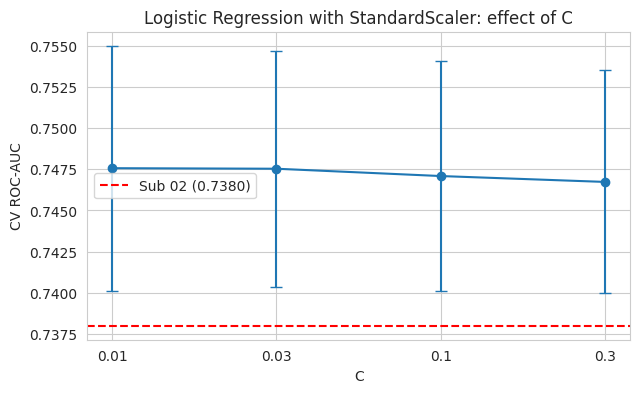

In [24]:
plt.figure(figsize=(7, 4))
plt.errorbar(c_results.C.astype(str), c_results['ROC-AUC'], yerr=c_results.Std, marker='o', capsize=4)
plt.axhline(sub02_lr, color='red', linestyle='--', label='Sub 02 (0.7380)')
plt.xlabel('C')
plt.ylabel('CV ROC-AUC')
plt.title(f'Logistic Regression with {best_scaler}: effect of C')
plt.legend()
plt.show()

## Results Comparison

In [25]:
best_c = c_results.loc[c_results['ROC-AUC'].idxmax()]
results.append({'Experiment': '3. Tuned C', 'Model': 'Logistic Regression',
                'Setting': f'C={best_c.C}, {best_scaler}', **best_c.drop('C').to_dict()})

summary = pd.DataFrame(results)
summary['Change vs Sub 02 LR'] = summary['ROC-AUC'] - sub02_lr
summary[['Experiment', 'Model', 'Setting', 'ROC-AUC', 'Std', 'Change vs Sub 02 LR',
         'Accuracy', 'Precision', 'Recall', 'F1']].round(4)

,Experiment,Model,Setting,ROC-AUC,Std,Change vs Sub 02 LR,Accuracy,Precision,Recall,F1
0,1. New features,Logistic Regression,"C=0.1, StandardScaler",0.7471,0.0070,0.0091,0.9030,0.6253,0.0932,0.1622
1,1. New features,Random Forest,min_samples_leaf=50,0.7280,0.0076,-0.0100,0.9001,0.7212,0.0146,0.0285
2,2. QuantileTransformer,Logistic Regression,"C=0.1, QuantileTransformer",0.7454,0.0071,0.0074,0.9028,0.6253,0.0885,0.1549
3,3. Tuned C,Logistic Regression,"C=0.01, StandardScaler",0.7476,0.0074,0.0096,0.9028,0.6249,0.0888,0.1555


In [26]:
pd.DataFrame({'Fold': range(1, 6), 'Sub 02 LR': sub02_folds, 'Sub 03 LR': best_c.Folds,
              'Difference': np.round(best_c.Folds - sub02_folds, 4)})

,Fold,Sub 02 LR,Sub 03 LR,Difference
0,1,0.7374,0.7506,0.0132
1,2,0.7479,0.7570,0.0091
2,3,0.7355,0.7464,0.0109
3,4,0.7438,0.7493,0.0055
4,5,0.7255,0.7344,0.0089


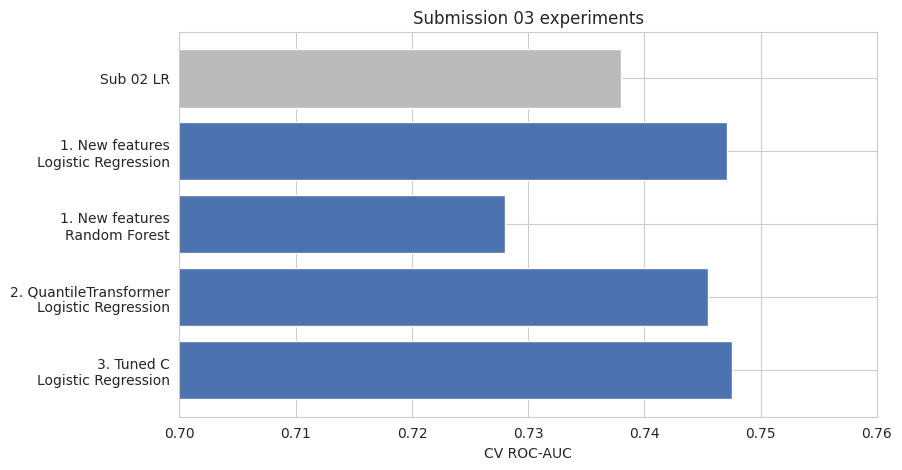

In [27]:
labels = ['Sub 02 LR'] + [f"{r['Experiment']}\n{r['Model']}" for r in results]
values = [sub02_lr] + [r['ROC-AUC'] for r in results]
plt.figure(figsize=(9, 5))
plt.barh(labels, values, color=['#BBBBBB'] + ['#4C72B0'] * len(results))
plt.xlim(0.70, 0.76)
plt.xlabel('CV ROC-AUC')
plt.title('Submission 03 experiments')
plt.gca().invert_yaxis()
plt.show()

## ROC Curves

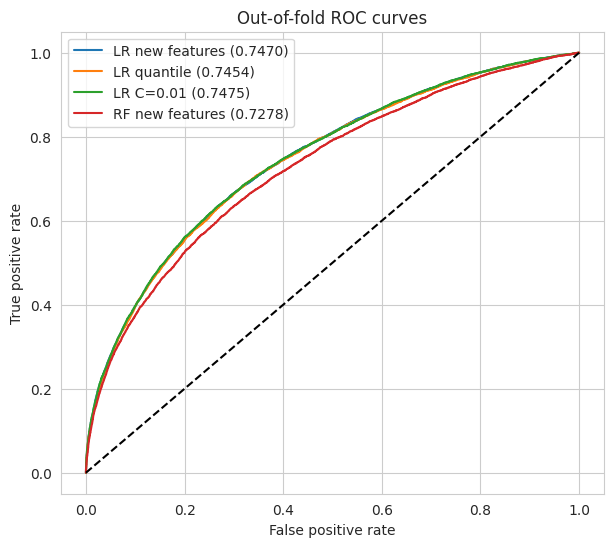

In [28]:
plt.figure(figsize=(7, 6))
for name in ['LR new features', 'LR quantile', f'LR C={best_c.C}', 'RF new features']:
    fpr, tpr, _ = roc_curve(y, oof[name])
    plt.plot(fpr, tpr, label=f'{name} ({roc_auc_score(y, oof[name]):.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Out-of-fold ROC curves')
plt.legend()
plt.show()

## Final Model

In [29]:
best = summary.loc[summary['ROC-AUC'].idxmax()]
if best.Model == 'Random Forest':
    model, prep = RandomForestClassifier(min_samples_leaf=50, n_jobs=-1, random_state=SEED), prep_standard
elif best.Experiment.startswith('3'):
    model, prep = LogisticRegression(C=best_c.C, max_iter=2000), best_prep
elif best.Experiment.startswith('2'):
    model, prep = LogisticRegression(C=0.1, max_iter=2000), prep_quantile
else:
    model, prep = LogisticRegression(C=0.1, max_iter=2000), prep_standard

final = Pipeline([('prep', prep), ('model', clone(model))])
final.fit(X, y)
print('Selected:', best.Model, '|', best.Setting, f"| CV ROC-AUC {best['ROC-AUC']:.4f}")

Selected: Logistic Regression | C=0.01, StandardScaler | CV ROC-AUC 0.7476


## Most Influential Features

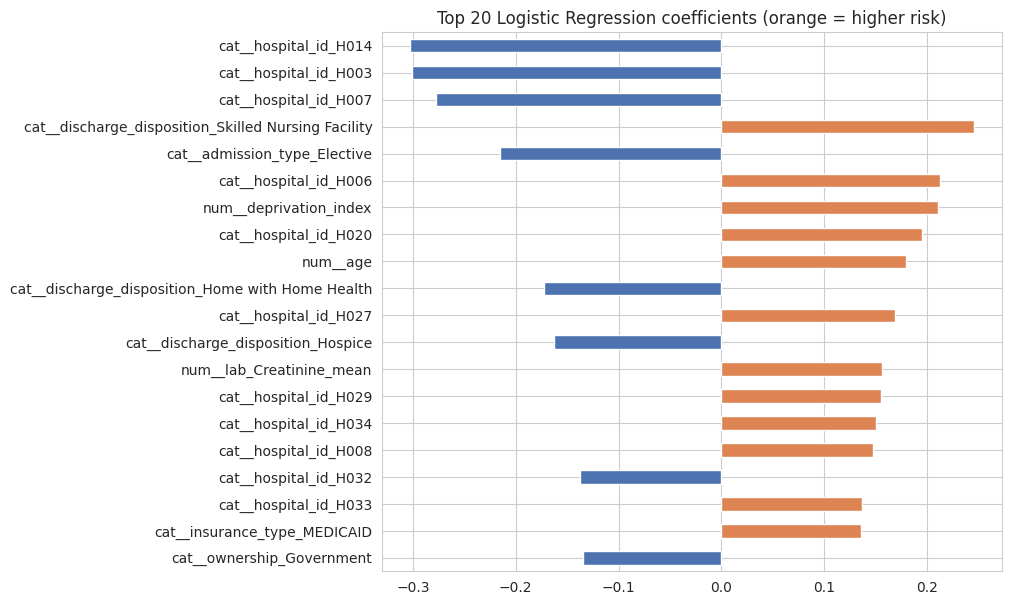

In [30]:
if best.Model == 'Logistic Regression':
    names = final.named_steps['prep'].get_feature_names_out()
    coef = pd.Series(final.named_steps['model'].coef_[0], index=names)
    top = coef.reindex(coef.abs().sort_values().index).tail(20)
    top.plot.barh(figsize=(8, 7), color=np.where(top > 0, '#DD8452', '#4C72B0'))
    plt.title('Top 20 Logistic Regression coefficients (orange = higher risk)')
    plt.show()

## Submission File

In [31]:
submission = pd.DataFrame({'encounter_id': X_test.encounter_id,
                           'readmit_30d': final.predict_proba(X_test)[:, 1]})
submission.to_csv('submission.csv', index=False)
print(submission.shape)
submission.head()

(32812, 2)


,encounter_id,readmit_30d
0,E14322700,0.072808
1,E10891017,0.095803
2,E15846764,0.124303
3,E35399048,0.049482
4,E18403456,0.025929
